## Multi-Agent Swarm Architecture
![alt text](image-6.png)

In [1]:
%%capture --no-stderr
%pip install langgraph-swarm
%pip install --quiet -U langchain_core langgraph langchain_openai

In [2]:
import os, getpass

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("OPENAI_API_KEY")

In [17]:
import datetime
from collections import defaultdict
from typing import Callable
from langchain_core.runnables import RunnableConfig
from langchain_openai import ChatOpenAI

from langchain.agents import create_agent
from langgraph_swarm import create_handoff_tool, create_swarm
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore

llm = ChatOpenAI(model="gpt-4o")

In [18]:
RESERVATIONS = defaultdict(lambda: {"flight_info": {}, "hotel_info": {}})
TOMORROW = (datetime.date.today() + datetime.timedelta(days=1)).isoformat()
FLIGHTS = [
    {
        "departure_airport": "BOS",
        "arrival_airport": "JFK",
        "airline": "Jet Blue",
        "date": TOMORROW,
        "id": "1",
    }
]
HOTELS = [
    {
        "location": "New York",
        "name": "McKittrick Hotel",
        "neighborhood": "Chelsea",
        "id": "1",
    }
]

## Flight tools

In [19]:
def search_flights(departure_airport: str, arrival_airport: str, date: str) -> list[dict]:
    """Search for available flights."""
    return FLIGHTS

def book_flight(flight_id: str, config: RunnableConfig) -> str:
    """Book a flight given a flight ID."""
    user_id = config["configurable"].get("user_id")
    flight = next(f for f in FLIGHTS if f["id"] == flight_id)
    RESERVATIONS[user_id]["flight_info"] = flight
    return "Successfully booked flight"

## Hotel tools

In [20]:
def search_hotels(location: str) -> list[dict]:
    """Search for available hotels in a given location."""
    return HOTELS

def book_hotel(hotel_id: str, config: RunnableConfig) -> str:
    """Book a hotel given a hotel ID."""
    user_id = config["configurable"].get("user_id")
    hotel = next(h for h in HOTELS if h["id"] == hotel_id)
    RESERVATIONS[user_id]["hotel_info"] = hotel
    return "Successfully booked hotel"

## Handoff tools (Swarm Agents Communication)

In [21]:
transfer_to_hotel_assistant = create_handoff_tool(
    agent_name="hotel_assistant", description="Transfer user to the hotel-booking assistant."
)
transfer_to_flight_assistant = create_handoff_tool(
    agent_name="flight_assistant", description="Transfer user to the flight-booking assistant."
)

## Agent Prompt Generator

In [22]:
def make_prompt(base_system_prompt: str) -> Callable[[dict, RunnableConfig], list]:
    def prompt(state: dict, config: RunnableConfig) -> list:
        user_id = config["configurable"].get("user_id")
        current_reservation = RESERVATIONS[user_id]
        system_prompt = (
            base_system_prompt
            + f"\n\nUser's active reservation: {current_reservation}"
            + f"Today is: {datetime.datetime.now()}"
        )
        return [{"role": "system", "content": system_prompt}] + state["messages"]
    return prompt

## Create the Flight and Hotel Assistants
* Flight assistant
  * Search flights
  * Book flights
  * Transfers users to the hotel assistant
* Hotel assistant
  * Searches hotels
  * Books hotels
  * Transfers users to the flight assistant

In [23]:
flight_assistant = create_agent(
    llm,  # Fixed: was 'model', should be 'llm'
    [search_flights, book_flight, transfer_to_hotel_assistant],
    #system_prompt=make_prompt("You are a flight booking assistant"),
    system_prompt="You are a helpful flight booking assistant. You can search for flights and book them for users. You have access to current reservation information and can transfer users to the hotel assistant when needed.",
    name="flight_assistant",
)

hotel_assistant = create_agent(
    llm,  # Fixed: was 'model', should be 'llm'
    [search_hotels, book_hotel, transfer_to_flight_assistant],
    #system_prompt=make_prompt("You are a hotel booking assistant"),
    system_prompt="You are a helpful hotel booking assistant. You can search for hotels and book them for users. You have access to current reservation information and can transfer users to the flight assistant when needed.",
    name="hotel_assistant",
)

## Multi-Agent System (Swarm)

In [24]:
checkpointer = InMemorySaver() # short-term in-memory storage for checkpoints

builder = create_swarm(
    [flight_assistant, hotel_assistant],
    default_active_agent="flight_assistant"
)
app = builder.compile(checkpointer=checkpointer)

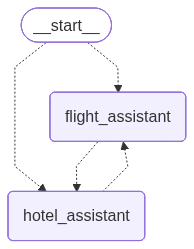

In [25]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [26]:
def print_stream(stream):
    """Helper function to print streaming output from the graph"""
    for chunk in stream:
        if "messages" in chunk:
            for message in chunk["messages"]:
                print(f"[{message.type}]: {message.content}")
        elif "agent" in chunk:
            print(f"🤖 Active Agent: {chunk['agent']}")
        else:
            print(f"📝 Update: {chunk}")
        print("-" * 50)

In [27]:
config = {"configurable": {"thread_id": "1", "user_id": "1"}}
result = app.invoke({
    "messages": [
        {
            "role": "user",
            "content": "i am looking for a flight from boston to ny tomorrow"
        }
    ],
}, config)

In [28]:
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================

i am looking for a flight from boston to ny tomorrow
================================== Ai Message ==================================
Tool Calls:
  search_flights (call_pt7nNpxz0UAdOwFWeqmtEZq8)
 Call ID: call_pt7nNpxz0UAdOwFWeqmtEZq8
  Args:
    departure_airport: BOS
    arrival_airport: JFK
    date: 2023-11-20
================================= Tool Message =================================
Name: search_flights

[{"departure_airport": "BOS", "arrival_airport": "JFK", "airline": "Jet Blue", "date": "2025-11-07", "id": "1"}]
================================== Ai Message ==================================

It seems there was a mistake in the flight search response, likely due to a data error. Let me reconfirm the available flights for tomorrow from Boston to New York.
Tool Calls:
  search_flights (call_F0lk3rYA7plZuwYHzw0f5Kd5)
 Call ID: call_F0lk3rYA7plZuwYHzw0f5Kd5
  Args:
    departure_airport: BOS
   

In [29]:
config = {"configurable": {"thread_id": "1", "user_id": "1"}}
result = app.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Now I'd like to book a hotel as well."
        }
    ],
}, config)

In [30]:
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================

i am looking for a flight from boston to ny tomorrow
================================== Ai Message ==================================
Tool Calls:
  search_flights (call_pt7nNpxz0UAdOwFWeqmtEZq8)
 Call ID: call_pt7nNpxz0UAdOwFWeqmtEZq8
  Args:
    departure_airport: BOS
    arrival_airport: JFK
    date: 2023-11-20
================================= Tool Message =================================
Name: search_flights

[{"departure_airport": "BOS", "arrival_airport": "JFK", "airline": "Jet Blue", "date": "2025-11-07", "id": "1"}]
================================== Ai Message ==================================

It seems there was a mistake in the flight search response, likely due to a data error. Let me reconfirm the available flights for tomorrow from Boston to New York.
Tool Calls:
  search_flights (call_F0lk3rYA7plZuwYHzw0f5Kd5)
 Call ID: call_F0lk3rYA7plZuwYHzw0f5Kd5
  Args:
    departure_airport: BOS
   